# One class SVM 

One-Class Support Vector Machine (One-Class SVM) is an unsupervised machine learning algorithm designed specifically for anomaly, outlier, or novelty detection by training exclusively on a single "normal" class of data

# For more information click the link below

https://docs.google.com/document/d/164jUPF02nMepX3qnkLvV1m_YjZNyoeMtoLm4o--nwEc/edit?usp=sharing

# Notes and interview question and answer

https://docs.google.com/document/d/1mOVE0-5o3fdDkQREiTXIZlzBExmiGV7Ic4tL74mgR34/edit?usp=sharing

# Coding

# Import libraries 

In [2]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_blobs                 # Generate synthetic normal data
from sklearn.svm import OneClassSVM                     # One-Class SVM anomaly detector
from sklearn.preprocessing import StandardScaler        # Standardize features

# Create normal data 


In [3]:
X_normal, _ = make_blobs(
    n_samples=500,                                      # Generate 500 normal observations
    centers=1,                                          # Create one main normal cluster
    cluster_std=1.0,                                    # Control the spread of normal observations
    random_state=42                                     # Make the dataset reproducible
)

print("Normal data shape:", X_normal.shape)             # 500 samples × 2 features

Normal data shape: (500, 2)


# Create artificial anomalies 

In [8]:
anomalies = np.array([
    [8, 8],                                             # Artificial anomaly
    [9, 7],                                             # Artificial anomaly
    [8, -7],                                            # Artificial anomaly
    [-8, 8],                                            # Artificial anomaly
    [-7, -8]                                            # Artificial anomaly
])

`Now combine them `

In [9]:
X = np.vstack([
    X_normal,                                            # Normal observations
    anomalies                                             # Artificial anomalies
])

print("Final data shape:", X.shape)                     # 505 samples × 2 features

Final data shape: (505, 2)


# Visualize the data 

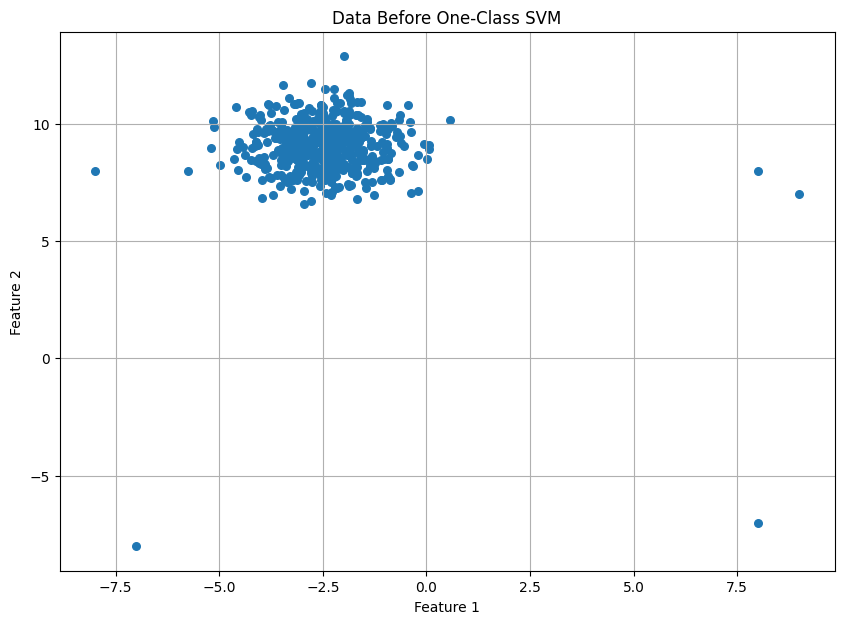

In [10]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Data Before One-Class SVM")

plt.grid()
plt.show()

# Scale the data 


Scaling is particularly important for SVM-based algorithms because distance and feature scale influence the learned boundary.

In [11]:
scaler = StandardScaler()                               # Create the standardization object

X_scaled = scaler.fit_transform(
    X                                                     # Standardize both features
)

# Create one class SVM 

In [ ]:
one_class_svm = OneClassSVM(
    kernel="rbf",                                        # Use a nonlinear RBF kernel to learn a flexible boundary, RBF allows One-Class SVM to learn a nonlinear boundary.
    nu=0.01,            # this is one of the most important parameters in One class SVM hyperparameters.                                 # Approximate upper bound on the fraction of training errors/anomalies
    gamma="scale"      # gamma controls how strongly individual observation influence the RBF decision boundry.                                 # Automatically determine a suitable RBF kernel width
)

# let's understnad the important parameters . 



# Train One-Class SVM 

In [13]:
one_class_svm.fit(
    X_scaled                                            # Learn the normal-data boundary
)

OneClassSVM(nu=0.01)

# Predict normal vs anomaly 


In [15]:
predictions = one_class_svm.predict(
    X_scaled                                            # Classify each observation relative to the learned normal boundary
)

print(predictions[:20])                                # Display the first 20 predictions

# Remember -
#  1 is normal 
# -1 anomaly


[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


# Extract anomalies 

In [16]:
anomaly_mask = predictions == -1                        # Create a Boolean mask for detected anomalies

X_anomalies = X[
    anomaly_mask                                        # Select observations classified as anomalies
]

print("Detected anomalies:", len(X_anomalies))          # Count detected anomalies

Detected anomalies: 17


# Visualize the result 


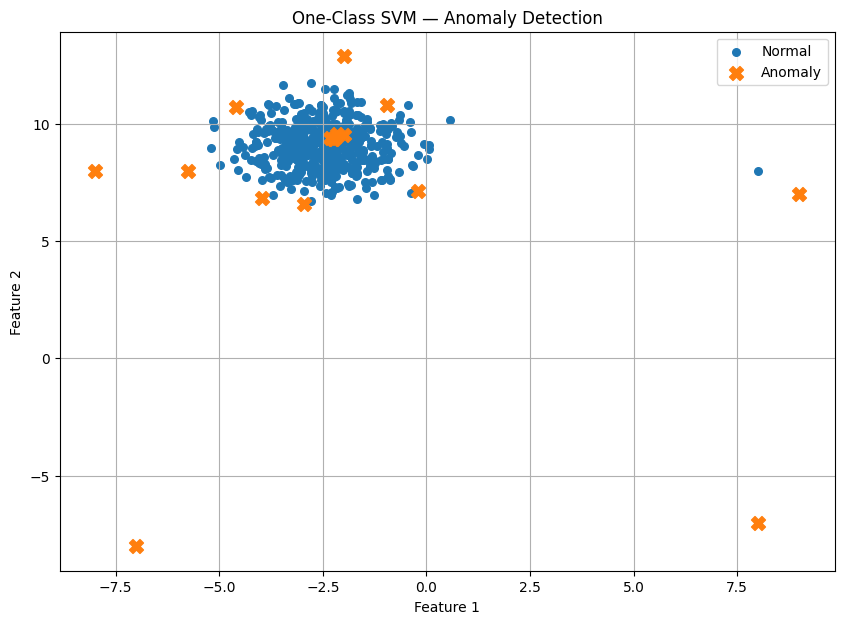

In [17]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                            # First feature
    X[:, 1],                                            # Second feature
    s=30,                                               # Normal point size
    label="Normal"
)

plt.scatter(
    X_anomalies[:, 0],                                  # First feature of detected anomalies
    X_anomalies[:, 1],                                  # Second feature of detected anomalies
    s=100,                                              # Make anomalies larger
    marker="X",                                         # Use X marker for anomalies
    label="Anomaly"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("One-Class SVM — Anomaly Detection")

plt.legend()
plt.grid()
plt.show()

# Decision function 

`One-Class SVM also gives us a score: `

In [18]:
scores = one_class_svm.decision_function(
    X_scaled                                            # Calculate the signed distance from the learned boundary
)

print(scores[:10])                                     # Display the first 10 decision scores

[0.00025974 0.01858349 0.01345459 0.0262701  0.02423367 0.01377008
 0.03226018 0.01444947 0.02143318 0.00965662]


# Experiment with nu

`This is one of the experiments you should actually do .`

In [19]:
for nu_value in [0.01, 0.02, 0.05, 0.10]:

    model = OneClassSVM(
        kernel="rbf",                                   # Use nonlinear RBF boundary
        nu=nu_value,                                    # Change expected outlier proportion
        gamma="scale"                                   # Automatically determine gamma
    )

    model.fit(
        X_scaled                                         # Learn the normal-data boundary
    )

    predictions = model.predict(
        X_scaled                                         # Detect normal observations and anomalies
    )

    print(
        f"nu={nu_value} → anomalies={sum(predictions == -1)}"
    )

nu=0.01 → anomalies=17
nu=0.02 → anomalies=19
nu=0.05 → anomalies=25
nu=0.1 → anomalies=53


# Experiment with gamma. 

In [20]:
for gamma_value in ["scale", 0.01, 0.1, 1]:

    model = OneClassSVM(
        kernel="rbf",                                   # Use nonlinear RBF kernel
        nu=0.01,                                        # Keep expected anomaly proportion fixed
        gamma=gamma_value                               # Change the flexibility of the boundary
    )

    model.fit(
        X_scaled                                         # Learn the normal-data boundary
    )

    predictions = model.predict(
        X_scaled                                         # Detect anomalies
    )

    print(
        f"gamma={gamma_value} → anomalies={sum(predictions == -1)}"
    )

gamma=scale → anomalies=17
gamma=0.01 → anomalies=4
gamma=0.1 → anomalies=4
gamma=1 → anomalies=40
